In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn import linear_model
from sklearn.linear_model import RidgeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [52]:
df_AQS=pd.read_csv('ds/LA_AQS_2023.csv')

## Using the EPA AQS data make a scatter plot of O3 vs NO2 concentrations and O3 vs PM2.5 concentrations.

1. Using these data as input, train a ridge classifier to predict if the measurements come from summer or winter.
2. What cost function are you using?
3. What is the optimal ridge penalty parameter based on your training data?
4. What is the optimal ridge penalty parameter on your validation data?
5. What is your final model error? (Be sure to report the most honest error assessment).
6. If you redo your train/validation splits, do you get the same answers?
7. Compare the ridge classifier with a logistic regression model. Which one performs the best?

In [55]:
df_o3 = df_AQS.loc[df_AQS['Parameter Name']=='Ozone']
df_o3_hourly=df_o3.loc[df_o3['Duration Description']=='1 HOUR']

# Date (Local), AQI
df_o3_hourly['Date (Local)']=pd.to_datetime(df_o3_hourly['Date (Local)'])
df_o3_hourly.head()

/var/folders/rv/6grd_c413pg00vmn_zyh8ms00000gn/T/ipykernel_1779/435737406.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_o3_hourly['Date (Local)']=pd.to_datetime(df_o3_hourly['Date (Local)'])


,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
20,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
64,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
204,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
228,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
271,6,37,1103,44201,1,34.06659,-118.22688,WGS84,Ozone,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [56]:
df_no2 = df_AQS.loc[df_AQS['Parameter Name']=='Nitrogen dioxide (NO2)']
df_no2_hourly=df_no2.loc[df_no2['Duration Description']=='1 HOUR']

# Date (Local), AQI
df_no2_hourly['Date (Local)']=pd.to_datetime(df_no2_hourly['Date (Local)'])
df_no2_hourly.head()

,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
1,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
19,6,37,1103,42602,1,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
29,6,37,1103,42602,1,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
41,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
44,6,37,1103,42602,3,34.06659,-118.22688,WGS84,Nitrogen dioxide (NO2),1 HOUR,...,20,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [57]:
df_pm = df_AQS.loc[df_AQS['Parameter Name']=='PM2.5 - Local Conditions']
df_pm_hourly=df_pm.loc[df_pm['Duration Description']=='1 HOUR']

# Date (Local), AQI
df_pm_hourly['Date (Local)']=pd.to_datetime(df_pm_hourly['Date (Local)'])
df_pm_hourly.head()

/var/folders/rv/6grd_c413pg00vmn_zyh8ms00000gn/T/ipykernel_1779/1456706348.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pm_hourly['Date (Local)']=pd.to_datetime(df_pm_hourly['Date (Local)'])


,State Code,County Code,Site Number,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Duration Description,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
30,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
73,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
92,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
237,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
280,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,.,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [58]:
import functools as ft
dfs = [df_pm_hourly, df_o3_hourly, df_no2_hourly]
df_merged = ft.reduce(lambda left, right: pd.merge(left, right, on='Date (Local)'), dfs)
df_merged.head()

,State Code_x,County Code_x,Site Number_x,Parameter Code_x,POC_x,Latitude_x,Longitude_x,Datum_x,Parameter Name_x,Duration Description_x,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,20,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [59]:
df_merged = df_merged.rename(columns={'Arithmetic Mean': 'Arithmetic Mean_no2', 'Arithmetic Mean_y': 'Arithmetic Mean_o3', 'Arithmetic Mean_x': 'Arithmetic Mean_pm2.5'})



<Axes: xlabel='Arithmetic Mean_o3', ylabel='Arithmetic Mean_no2'>

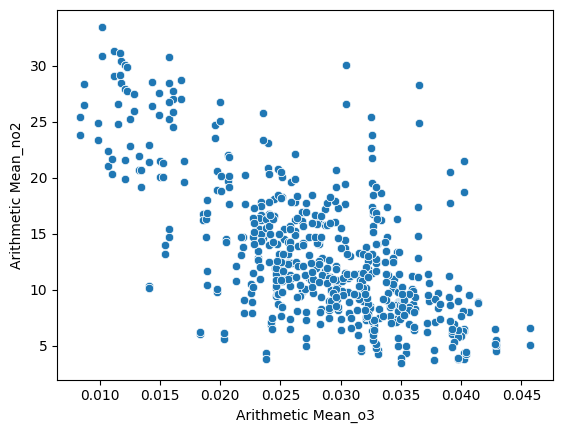

In [60]:
sns.scatterplot(data=df_merged, x="Arithmetic Mean_o3", y="Arithmetic Mean_no2")

<Axes: xlabel='Arithmetic Mean_o3', ylabel='Arithmetic Mean_pm2.5'>

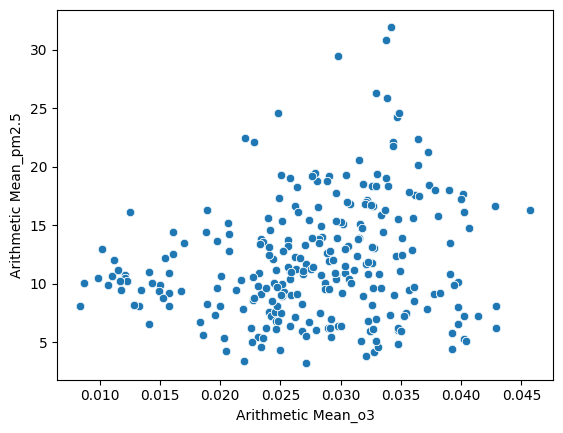

In [70]:
sns.scatterplot(data=df_merged, x="Arithmetic Mean_o3", y="Arithmetic Mean_pm2.5")

In [72]:
merged_array=df_merged.to_numpy()
merged_array

array([[6, 37, 1103, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       [6, 37, 1103, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       [6, 37, 1103, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       ...,
       [6, 37, 1103, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       [6, 37, 1103, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       [6, 37, 1103, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart']],
      shape=(1084, 100), dtype=object)

In [90]:
df_merged['Date (Local)']

0      2023-01-01
1      2023-01-01
2      2023-01-01
3      2023-01-01
4      2023-01-02
          ...    
1079   2023-09-29
1080   2023-09-30
1081   2023-09-30
1082   2023-09-30
1083   2023-09-30
Name: Date (Local), Length: 1084, dtype: datetime64[ns]

In [106]:
summer_mask = df_merged["Date (Local)"].dt.month.isin([6, 7, 8])
df_summer = df_merged[summer_mask]
df_summer = df_summer.sort_values(by="Date (Local)")
df_summer.head()

,State Code_x,County Code_x,Site Number_x,Parameter Code_x,POC_x,Latitude_x,Longitude_x,Datum_x,Parameter Name_x,Duration Description_x,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
596,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,14,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
597,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,14,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
598,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
599,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
600,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,15,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [108]:
winter_mask = df_merged["Date (Local)"].dt.month.isin([1, 2, 12])
df_winter = df_merged[winter_mask]
df_winter = df_winter.sort_values(by="Date (Local)")
df_winter.head()

,State Code_x,County Code_x,Site Number_x,Parameter Code_x,POC_x,Latitude_x,Longitude_x,Datum_x,Parameter Name_x,Duration Description_x,...,AQI,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source
0,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
1,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
2,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,17,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
3,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,16,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart
4,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,20,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart


In [110]:
df_winter["season"] = 0
df_summer["season"] = 1
df_combined = pd.concat([df_winter, df_summer], ignore_index=True)


In [112]:
df_combined.head()

,State Code_x,County Code_x,Site Number_x,Parameter Code_x,POC_x,Latitude_x,Longitude_x,Datum_x,Parameter Name_x,Duration Description_x,...,Daily Criteria Indicator,Tribe Name,State Name,County Name,City Name,Local Site Name,Address,MSA or CBSA Name,Data Source,season
0,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart,0
1,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart,0
2,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart,0
3,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart,0
4,6,37,1103,88101,3,34.06659,-118.22688,WGS84,PM2.5 - Local Conditions,1 HOUR,...,Y,NaN,California,Los Angeles,Los Angeles,Los Angeles-North Main Street,"1630 N MAIN ST, LOS ANGELES","Los Angeles-Long Beach-Anaheim, CA",AQS Data Mart,0


In [116]:
from sklearn.preprocessing import StandardScaler

In [132]:
X = df_combined[["Arithmetic Mean_o3", "Arithmetic Mean_no2", "Arithmetic Mean_pm2.5"]]
y = df_combined["season"]

In [134]:
# 60 Train: 20 Val: 20 Test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

### 1. Using these data as input, train a ridge classifier to predict if the measurements come from summer or winter.

In [170]:
clf = RidgeClassifier().fit(X, y)
clf.score(X, y)

0.8443708609271523

The ridge classifier is able to predict 84.44% of the time whether or not measurements are coming from summer or winter

### 2. What cost function are you using?

Regularlized MSE

### 3. What is the optimal ridge penalty parameter based on your training data?

Alpha is being evealuated on the training data and is close to zero

In [183]:
alphas = np.logspace(-4, 4, 50)
train_scores = []

for a in alphas:
    clf = RidgeClassifier(alpha=a).fit(X, y)
    train_scores.append(clf.score(X, y))  # Accuracy

train_alpha = alphas[np.argmax(train_scores)]
print(f"Optimal alpha: {train_alpha}")

Optimal alpha: 0.0062505519252739694


### 4. What is the optimal ridge penalty parameter on your validation data?

In [190]:
from sklearn.linear_model import RidgeClassifierCV

alpha_candidates = np.logspace(-3, 3, 100)

clf_cv = RidgeClassifierCV(alphas=alpha_candidates, scoring="accuracy").fit(
    X_train_scaled, y_train
)

print(f"Optimal alpha (Validation): {clf_cv.alpha_}")

Optimal alpha (Validation): 0.001


Alpha for validation is 0.001

### 5. What is your final model error? (Be sure to report the most honest error assessment).

In [196]:
from sklearn.metrics import zero_one_loss

final_model = RidgeClassifier(alpha=best_alpha_val).fit(X_train_scaled, y_train)
test_predictions = final_model.predict(X_test_scaled)

final_error = zero_one_loss(y_test, test_predictions)
print(f"Model Error: {final_error:.4f}")
print(f"Model Accuracy: {(1 - final_error) * 100:.2f}%")

Model Error: 0.1074
Model Accuracy: 89.26%


### 6. If you redo your train/validation splits, do you get the same answers?

Most likely not because there are small variations introduced based on the chunks of dataset we are setting between training, testing, and validation

### 7. Compare the ridge classifier with a logistic regression model. Which one performs the best?

In [203]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import zero_one_loss

# redoing the ridge class
ridge_model = RidgeClassifierCV(alphas=np.logspace(-3, 3, 100)).fit(
    X_train_scaled, y_train
)
ridge_error = zero_one_loss(y_test, ridge_model.predict(X_test_scaled))

# doing log regress
log_model = LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000)
log_model.fit(X_train_scaled, y_train)
log_error = zero_one_loss(y_test, log_model.predict(X_test_scaled))

print(f"Ridge Class Error:    {ridge_error:.4f}")
print(f"Logistic Regress Error: {log_error:.4f}")



Ridge Class Error:    0.1240
Logistic Regress Error: 0.0992


/Users/kaylena/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Based on what I got, the log regression performs better than the ridge classification.